# IoT-based Indoor Occupancy Detection

# **Introduction**
​
Person detection in an embedded IoT device without the use of a computer vision solution refers to the ability to detect the presence of a person in a given environment using sensors and signal processing techniques instead of relying on visual image analysis.
​
Typically, this type of person detection solution is achieved by leveraging various types of sensors, such as passive infrared (PIR) sensors, ultrasonic sensors, and radar sensors, which can detect physical changes in the environment caused by the presence of a person, such as body heat or movement.
​
Signal processing techniques are then applied to the sensor data to detect and differentiate the signal patterns associated with a person's presence from other environmental noise. Machine learning algorithms may also be used to improve the accuracy of the person detection system.
​
By using sensors and signal processing techniques, this type of person detection system can be implemented in an embedded IoT device with limited computing resources, making it suitable for a wide range of applications, such as home automation, security systems, and smart buildings.
​
​


# **Reading Dataset**

This dataset is used for binary classification and contains experimental data related to the likelihood of a room being occupied based on five environmental factors: temperature, humidity, light, and carbon dioxide (CO2) and humidity ratio levels.

The dataset consists of five features and a target variable. The features are temperature, humidity, light,humidity ratio and CO2 levels, while the target variable indicates the likelihood of room occupancy. 

A target value of 1 indicates that the room is likely to be occupied, while a target value of 0 indicates that the room is not likely to be occupied.

In [ ]:
import pandas as pd
df = pd.read_csv('Occupancy.csv')

# **Importing Required Liberaries**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report,confusion_matrix
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import GradientBoostingClassifier

# **Describing Dataset**

In this section we can retrive some sort of information about dataset. This data is important from two point od view:

  **1- Undrestanding the structure of database:** By using this information we can gain insights into    structure, such as the number and type of the columns, and relationships between them. This information can help us understand how data is organized within the database and design more effective queries to retrieve the desired information.

  **2- Ensuring data quality:** Examining initial information can help us identify potential data quality issues, such as missing or inconsistent data, which could affect the accuracy of our analysis 
  
  

**This section contains below information:**

1. The first command displays dimention of dataset
2. The second command reveals the column names of dataset:

   **Feature set:** Temperature, Humidity, Light, CO2, HumidityRatio
   
   **Target:**      Occupancy
   
3. The third command reveals overall information about dataset, contains information extracted by commands 1 to 3

4. The forth command compare values of target in terms of their quantity

5. The fifth command visualize values of target in terms of their quantity



In [ ]:
print("1 - Dimention of dataset: " , df.shape)
print(80*"=")

print("2 - Dataset Columns: " ,df.columns)
print(80*"=")

#print("1 - Features of Dataset: " , features)
#print(80*"=")

print("3 - Overall Information about dataset: ")
print(df.info())
print(80*"=")

print("4 - Compare the count of occupancy status:\n",df["Occupancy"].value_counts())
print(80*"=")

print("5 - Visualize the count of occupancy status:",sns.countplot(x="Occupancy", data=df))


# **Analysing Dataset values**

1. The first command displays the five rows of dataset
2. The second command return statisctic info for the numerical columns which is also useful. For instance by analysing this information it is revealed that:
   Light and CO2 with relative small means and stds (standard deviations), they both have large         max (maximun) value, which indicate that these two columns contain outliers.


In [ ]:
print("1 - Five rows of dataset:\n ",df.head())
print(80*"=")

print("2 - Statisctic info for the numerical columns:\n ", df.describe())
print(80*"=")

print("3- statisctic info for the numerical columns based on whether the room is occupied by people or not:\n",df.groupby(["Occupancy"]).describe())
print(80*"=")


# **Cleaning Dataset**

As null values affect the accuracy of the ML models, finding missing values of dataframe is one of the most important steps of data pre-processing and can be done by using pandas libarary. In this case, either these null values are removed or filled by different ways. 

1. The first command, return a new dataframe in which every column tells us whether or not that particular value is nan.

2. isnull() has same functionality as isna(), we can use sum() operation to count the number of null values in each column of dataframe

2. Counting the number of null values in each column of dataframe using isna()

In [ ]:
print("1 - Finding missing values using isna() function:  ",df.isna())
print(80*"=")

print("2 - Finding the count of missing values using isnull() function:  ",df.isnull().sum())
print(80*"=")

print("3 - Finding the count of missing values using isna() function:  ",df.isna().sum())
print(80*"=")

# **Filling missing data**

Replacing some random values of tempretaure column with null to compare the result of various methods of filling missing values.

    1: Fill null values with 0

    2: Fill null values with mean value

    3: Fill null values with previous data

    4: Fill null values using interpolation method

In [ ]:
f, ax = plt.subplots(nrows=4, ncols=1, figsize=(15, 12))
df = pd.read_csv('Occupancy.csv')
df = df.sample(frac=0.005)

df.loc[df.sample(frac=0.1).index,'Temperature'] = np.nan
df.loc[df[27:31].index,'Temperature'] = np.nan


print("Sample set size:", df.shape[0])
print("Count of null data:", df['Temperature'].isna().sum())

sns.lineplot(x=df.date, y=df.Temperature.fillna(0), ax=ax[0], color='darkorange', label = 'modified')
sns.lineplot(x=df.date, y=df.Temperature.fillna(np.inf), ax=ax[0], color='dodgerblue', label = 'original')
ax[0].set_title('Fill NaN with 0', fontsize=14)
ax[0].set_ylabel(ylabel='Volume C10 Petrignano', fontsize=14)

mean_val = df.Temperature.mean()
sns.lineplot(x=df.date, y=df.Temperature.fillna(mean_val), ax=ax[1], color='darkorange', label = 'modified')
sns.lineplot(x=df.date, y=df.Temperature.fillna(np.inf), ax=ax[1], color='dodgerblue', label = 'original')
ax[1].set_title(f'Fill NaN with Mean Value ({mean_val:.0f})', fontsize=14)
ax[1].set_ylabel(ylabel='Volume C10 Petrignano', fontsize=14)

sns.lineplot(x=df.date, y=df.Temperature.ffill(), ax=ax[2], color='darkorange', label = 'modified')
sns.lineplot(x=df.date, y=df.Temperature.fillna(np.inf), ax=ax[2], color='dodgerblue', label = 'original')
ax[2].set_title(f'FFill', fontsize=14)
ax[2].set_ylabel(ylabel='Volume C10 Petrignano', fontsize=14)

sns.lineplot(x=df.date, y=df.Temperature.interpolate(), ax=ax[3], color='darkorange', label = 'modified')
sns.lineplot(x=df.date, y=df.Temperature.fillna(np.inf), ax=ax[3], color='dodgerblue', label = 'original')
ax[3].set_title(f'Interpolate', fontsize=14)
ax[3].set_ylabel(ylabel='Volume C10 Petrignano', fontsize=14)


plt.tight_layout()
plt.show()

df = pd.read_csv('Occupancy.csv')


# **Analysing histogram**

A histogram is a graphical representation of the distribution of data.
By examining the shape of the histogram, we can gain insights into the underlying distribution of the data, such as whether it is symmetric or skewed, and whether it has any outliers.
    
For instance in below plot, we see that the Humidity and Temperature are normally distributed, while Light and CO2 are prominently skewed left.

In [ ]:
f, ax = plt.subplots(nrows=1, ncols=4, figsize=(20, 4),constrained_layout=True)

features = ["Temperature", "Humidity","Light","CO2"]
f.suptitle('Histogram and its Smooth Version of four selected features regardless of room occupancy:', fontsize=16)
df[features].hist(figsize=(15, 10),ax=ax);
df[features].plot(kind="density", subplots=True, layout=(1, 4), sharex=False, figsize=(20, 4));

print("\n\n\n\n")
f, ax = plt.subplots(nrows=1, ncols=4, figsize=(20, 4))
f.suptitle('Histogram and its Smooth Version of four selected features when room is occupied by human:', fontsize=12)
df[df["Occupancy"]==1][features].hist(figsize=(15, 10),ax=ax);

f, ax = plt.subplots(nrows=1, ncols=4, figsize=(20, 4))
f.suptitle('Histogram and its Smooth Version of four selected featureswhen room is not occupied by human:', fontsize=12)
df[df["Occupancy"]==0][features].hist(figsize=(15, 10),ax=ax);

# **Analyzing a boxplot and violin plot**

Analyzing a boxplot and violin plot can be helpful in several ways:

**1:** Visualizing distribution: Both boxplots and violin plots provide a visual representation of the distribution of the data. Boxplots display the distribution of data based on quartiles, while violin plots display the distribution using a kernel density estimation. Both types of plots allow us to quickly visualize the spread, skewness, and central tendency of the data.

**2:** Identifying outliers: Boxplots are particularly useful for identifying outliers in the data. Outliers are data points that fall outside the whiskers of the boxplot, indicating that they are either very high or very low compared to the majority of the data points. By identifying outliers, we can investigate potential data quality issues or errors in the data.

**3:** Comparing distributions: Boxplots and violin plots are also useful for comparing the distribution of multiple datasets. By displaying multiple boxplots or violin plots side-by-side, we can compare their shapes, spread, and central tendency. This can help us identify differences or similarities between datasets and draw insights from the comparisons.

**4:** Understanding variability: Both boxplots and violin plots provide a visual representation of variability in the data. For example, a wider box or violin indicates greater variability in the data, while a narrower box or violin indicates less variability.

In [ ]:
_, axes = plt.subplots(1, 6, sharey=True, figsize=(20, 4))
print(df["Temperature"].describe())
print(80*"=")
print("\n\n")
print("Figure 1 and 2 Visualize temperature using BoxPlot and ViolinPlot regardless of occupancy status")
print("Figure 3 and 4 Visualize temperature using BoxPlot and ViolinPlot when room is occupied by human")
print("Figure 5 and 6 Visualize temperature using BoxPlot and ViolinPlot when room is not occupied by human")
print(80*"=")
sns.boxplot(data=df["Temperature"], ax=axes[0]);
sns.violinplot(data=df["Temperature"], ax=axes[1]);


sns.boxplot(data=df[df["Occupancy"]==1]["Temperature"], ax=axes[2]);
sns.violinplot(data=df[df["Occupancy"]==1]["Temperature"], ax=axes[3]);

data=df[df["Occupancy"]==0]["Temperature"].reset_index(drop = True)
sns.boxplot(data=data, ax=axes[4]);
sns.violinplot(data=data, ax=axes[5]);


**Analyzing plot and boxplot of features regarding occupancy status**

In [ ]:
def occupancy_plot(df, cat):
    #fig, (ax1, ax2,ax3) = plt.subplots(1, 3, figsize=(20,4))
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20,4))
    
    fig.suptitle(cat)
    ax1.plot(np.where(df.Occupancy==1, df[cat], None), label='Occupied')
    ax1.plot(np.where(df.Occupancy==0, df[cat], None), label='Vacant', ls='--')
    ax1.grid()
    ax1.legend()
    
    ax2.boxplot([df[cat][df.Occupancy==1], df[cat][df.Occupancy==0], df[cat]])
    ax2.set_xticklabels(['Occupancy', 'Vacant', 'Overall'])
    
for i in range(1, 6):
    occupancy_plot(df, df.columns[i])

# **Removing outliers**

As it is mentioned, by statistic anayzing of Light and CO2 and Temperature values it is revealed that, these features with relative small means and stds (standard deviations), they have large max (maximun) value, which indicate that these three columns contain outliers.

In this section we try to remove these outliers to prepare data for further analyzing.

In [ ]:
df2 = df
df2 = df2[np.abs(df2.Temperature - df2.Temperature.mean()) <= 2*df2.Temperature.std()]
print("1. Removing the Outliers on 'Temperature' has reduced the data size from {} to {}.".format(len(df), len(df2)))
print("\n")
df = df2[np.abs(df2.Light - df2.Light.mean()) <= 2*df2.Light.std()]
print("2. Removing the Outliers on 'Light' has reduced the data size from {} to {}.".format(len(df2), len(df)))
print("\n")
df2 = df[np.abs(df.CO2 - df.CO2.mean()) <= 2*df2.CO2.std()]
print("3. Removing the Outliers on 'CO2' has reduced the data size from {} to {}.".format(len(df), len(df2)))
print("\n")

# **Analyzing boxplots before & after removing outliers**

The left plots display boxplots of features contain outliers while the right ones shows their relative boxplots after removing outliers.

It is obvious that removing outliers leads to decreasing difference of maxilum and mean values of selected features.

In [ ]:
dfOriginal = pd.read_csv('Occupancy.csv')
def compare_Boxplots(df,dfOriginal, categories):
    for cat in categories:
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20,4))

        fig.suptitle(cat)
        ax1.boxplot([dfOriginal[cat][dfOriginal.Occupancy==1], dfOriginal[cat][dfOriginal.Occupancy==0], dfOriginal[cat]])
        ax1.set_xticklabels(['Occupancy', 'Vacant', 'Overall'])

        ax2.boxplot([df[cat][df.Occupancy==1], df[cat][df.Occupancy==0], df[cat]])
        ax2.set_xticklabels(['Occupancy', 'Vacant', 'Overall'])
    
compare_Boxplots(df,dfOriginal, ["Temperature"])

# **Correlation Matrix**

A correlation matrix shows the correlation coefficients between variables, while a heatmap visualizes these correlations using colors. 

They are important because they allow you to quickly identify relationships between variables, visualize patterns in the data, and select important features for modeling.

In [ ]:
# Drop non-numerical variables
_, axes = plt.subplots(nrows=1, ncols=1, figsize=(8, 5))
numerical = list(set(df.columns)- {"date"})
corr_matrix = df[numerical].corr()
display(corr_matrix)

sns.heatmap(corr_matrix,ax=axes);
# corr_matrix

# **Predicting room occupancy using Machine Learning**

Predicting room occupancy usning machine learning techniques. To evaluate performance of these methods five metrices are used:

**1: Accuracy:** The percentage of correctly classified instances by the total number of instance

**2: True positive (sensitivity or recall):**  The proportion of positive instances that were correctly classified by the model out of the total number of positive instances in the dataset.

**3: True Negative (specificity):**  The proportion of negative instances that were correctly classified by the model out of the total number of negative instances in the dataset.

**4: False positive  :**  The proportion of negative instances that were incorrectly classified by the model out of the total number of negative instances in the dataset.

**5: False negative :**  The proportion of positive instances that were incorrectly classified by the model out of the total number of positive instances in the dataset.

**6: ROC curve :** A visual representation of the trade-off between sensitivity (true positive rate) and specificity (true negative rate).  A good classifier will have an ROC curve that closely hugs the top-left corner of the graph, indicating high sensitivity and specificity across a range of thresholds. 
The closer the curve is to the diagonal line (representing a random classifier), the poorer the performance of the model.
The **area under the ROC curve (AUC)** A perfect classifier will have an AUC of 1, while a random classifier will have an AUC of 0.5.


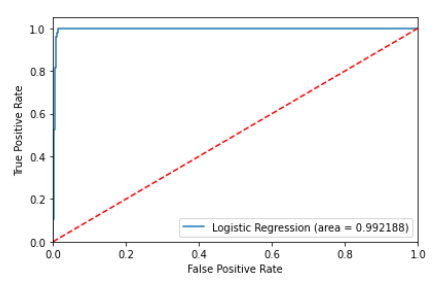


In [ ]:


# Create a dataframe that used to store data from confusion matrix and accuracy 
result = pd.DataFrame(columns=[
    'Classifier',
    'True Negative',
    'False Postive',
    'False Negative',
    'True Positive',
    'Classifier Accuracy',
    'Precision',
    'Recall',
    'F1 Score'
])


def accuracy_vis(xtest, ytest, ypred, predit_proba,plotFlag):
    # Confusion Matrix Visulation
    cm = confusion_matrix(ytest, ypred)
    if plotFlag:
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14,4))
        x_axis_labels = ['Actual Postive', 'Actual Negative']
        y_axis_labels = ['Predicted Postive', 'Predicted Negative']
        sns.heatmap(cm, fmt=".0f", annot=True, linewidths=.5, ax=ax1, 
                    cmap="YlGnBu", xticklabels=x_axis_labels)
        ax1.set_yticklabels(y_axis_labels, rotation=0, ha='right')

        # ROC Curve Visulation
        logit_roc_auc = roc_auc_score(ytest, ypred)
        fpr, tpr, thresholds = roc_curve(ytest, predit_proba[:,1])
        ax2.plot(fpr, tpr, label='Logistic Regression (area = {})'.format(round(logit_roc_auc,6)))
        ax2.plot([0, 1], [0, 1],'r--')
        ax2.set_xlim([0.0, 1.0])
        ax2.set_ylim([0.0, 1.05])
        ax2.set_xlabel('False Positive Rate')
        ax2.set_ylabel('True Positive Rate')
        ax2.legend()

        plt.show()
    return(confusion_matrix(ytest, ypred).ravel())

# **Machine Learning methods**

Using 5 different machine learning methods to predict room occupancy:

1. Logistic Regression
2. Decision Tree
3. Random Forest
4. K-Nearest Neighbors
5. Gradient Boosting


In [ ]:
def applyModel(df,selectedModel,plotFlag=True):
    
    df2=df
    X, Y = df2.iloc[:,1:-1], df2.iloc[:,-1]
    X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.25, random_state=0)

    modelTitle = selectedModel[0]
    absTitle = selectedModel[1]
    model=""
    
    if modelTitle == "Logistic Regression":
        model = LogisticRegression()
        
    elif modelTitle == "DecisionTree":
        model = DecisionTreeClassifier()
        
    elif modelTitle == "RandomForest":
        model = RandomForestClassifier(n_estimators= 10)
        
    elif modelTitle == "K-Nearest Neighbors":
        model = KNeighborsClassifier(n_neighbors=int(np.sqrt(len(X_train))), metric= 'minkowski' ,p= 2)
        
        
        
    elif modelTitle == "Gradient Boosting":
        model = GradientBoostingClassifier()

    if model != "":
        model.fit(X_train, Y_train)
        Y_pred, model_score, predit_proba = model.predict(X_test), model.score(X_test, Y_test), model.predict_proba(X_test)

        # Additional evaluation metrics (Occupancy = 1 is the positive class)
        precision = precision_score(Y_test, Y_pred, zero_division=0)
        recall = recall_score(Y_test, Y_pred, zero_division=0)
        f1 = f1_score(Y_test, Y_pred, zero_division=0)

        if plotFlag:
            print('Accuracy of ',modelTitle,' Classifier on test set: {:.6f}%'.format(model_score*100))
            print('Precision: {:.6f}'.format(precision))
            print('Recall:    {:.6f}'.format(recall))
            print('F1 Score:  {:.6f}'.format(f1))
       
        tn, fp, fn, tp = accuracy_vis(X_test, Y_test, Y_pred, predit_proba,plotFlag)
        result.loc[absTitle] = [
            modelTitle, tn, fp, fn, tp, round(model_score*100, 6),
            round(precision, 6), round(recall, 6), round(f1, 6)
        ]

In [ ]:
applyModel(df,["Logistic Regression","LR"])

applyModel(X_train, Y_train,X_test, Y_test,["LogisticRegression"])

In [ ]:
applyModel(df,["DecisionTree","DT"])

In [ ]:
applyModel(df,["RandomForest","RF"])

In [ ]:
applyModel(df,["K-Nearest Neighbors","KNN"])

In [ ]:
applyModel(df,["Gradient Boosting","GB"])

# **Comparing performance of Machine Learning methods**
Reveal the performance of machine learning methods after removing the outliers

In [ ]:
dfNew=result.copy()
print("Classifier Accuracy after removing outliers\n")
result.sort_values('Classifier Accuracy', ascending=False)


# **Applying Machine Learning methods before removing outliers**

Predicting room occupancy before removing outliers of dataset.

In [ ]:
applyModel(dfOriginal,["Logistic Regression","LR"],False)
applyModel(dfOriginal,["DecisionTree","DT"],False)
applyModel(dfOriginal,["Gradient Boosting","GB"],False)
applyModel(dfOriginal,["K-Nearest Neighbors","KNN"],False)
applyModel(dfOriginal,["RandomForest","RF"],False)


# **Comparing performance of Machine Learning methods**
Reveal the performance of machine learning methods before removing the outliers

In [ ]:
print("Classifier Accuracy Before removing outliers\n")
result.sort_values('Classifier Accuracy', ascending=False)